In [196]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import seaborn as sns 


In [197]:
#load and select data

# works from the project folder or file folder
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

markets = pd.read_parquet(
    ROOT / "data" / "eda" / "20260916_v2" / "markets.parquet"
)

candidate_features = [
    "observed_wallet_count",
    "wallet_trade_count",
    "account_activity_per_observed_day",
    "mean_wallet_trade_notional",
    "wallet_activity_hhi",
    "forecast_certainty",
    "price_movement_pp_per_hour",
]

# set threshold for min number of price intervals
MIN_PRICE_INTERVALS = 6

# remove  markets without metrics for all features
complete = (
    markets[candidate_features].notna().all(axis=1)
    & markets["usable_price_intervals"].ge(MIN_PRICE_INTERVALS)
)

# remove  markets without metrics for all features

# create a copy of just the numeric features for scaling
X_candidates_raw = (
    markets.loc[complete, candidate_features]
    .astype(float)
    .copy()
)

# metadata for the markets included in the analysis
metadata = markets.loc[
    complete,
    [
        "market_id",
        "topic",
        "question",
        "window_hours",
        "usable_price_intervals",
        "price_movement_observed_hours",
    ],
].copy()

print(f"Included markets: {len(X_candidates_raw)} of {len(markets)}")
print(f"Candidate table shape: {X_candidates_raw.shape}")

display(metadata["topic"].value_counts())

Included markets: 492 of 565
Candidate table shape: (492, 7)


topic
Politics     197
Economics    164
Sports       131
Name: count, dtype: int64

In [198]:
# log and standardize 

candidate_log_features = [
    "observed_wallet_count",
    "wallet_trade_count",
    "account_activity_per_observed_day",
    "mean_wallet_trade_notional",
    "price_movement_pp_per_hour",
]

# log transform selected features then standardize
X_candidates_transformed = X_candidates_raw.copy()
X_candidates_transformed[candidate_log_features] = np.log1p(X_candidates_raw[candidate_log_features])

candidate_scaler = StandardScaler()


X_candidates_scaled = pd.DataFrame(
    candidate_scaler.fit_transform(X_candidates_transformed),
    columns=candidate_features,
    index=X_candidates_transformed.index,
)

# X_candidates_scaled.head()


# confirm that the scaling worked 
confirm_scale = pd.DataFrame({
    "mean": X_candidates_scaled.mean(),
    "standard_deviation": X_candidates_scaled.std(ddof=0),
})

confirm_scale.round(6)

,mean,standard_deviation
observed_wallet_count,0.0,1.0
wallet_trade_count,0.0,1.0
account_activity_per_observed_day,-0.0,1.0
mean_wallet_trade_notional,0.0,1.0
wallet_activity_hhi,-0.0,1.0
forecast_certainty,0.0,1.0
price_movement_pp_per_hour,0.0,1.0


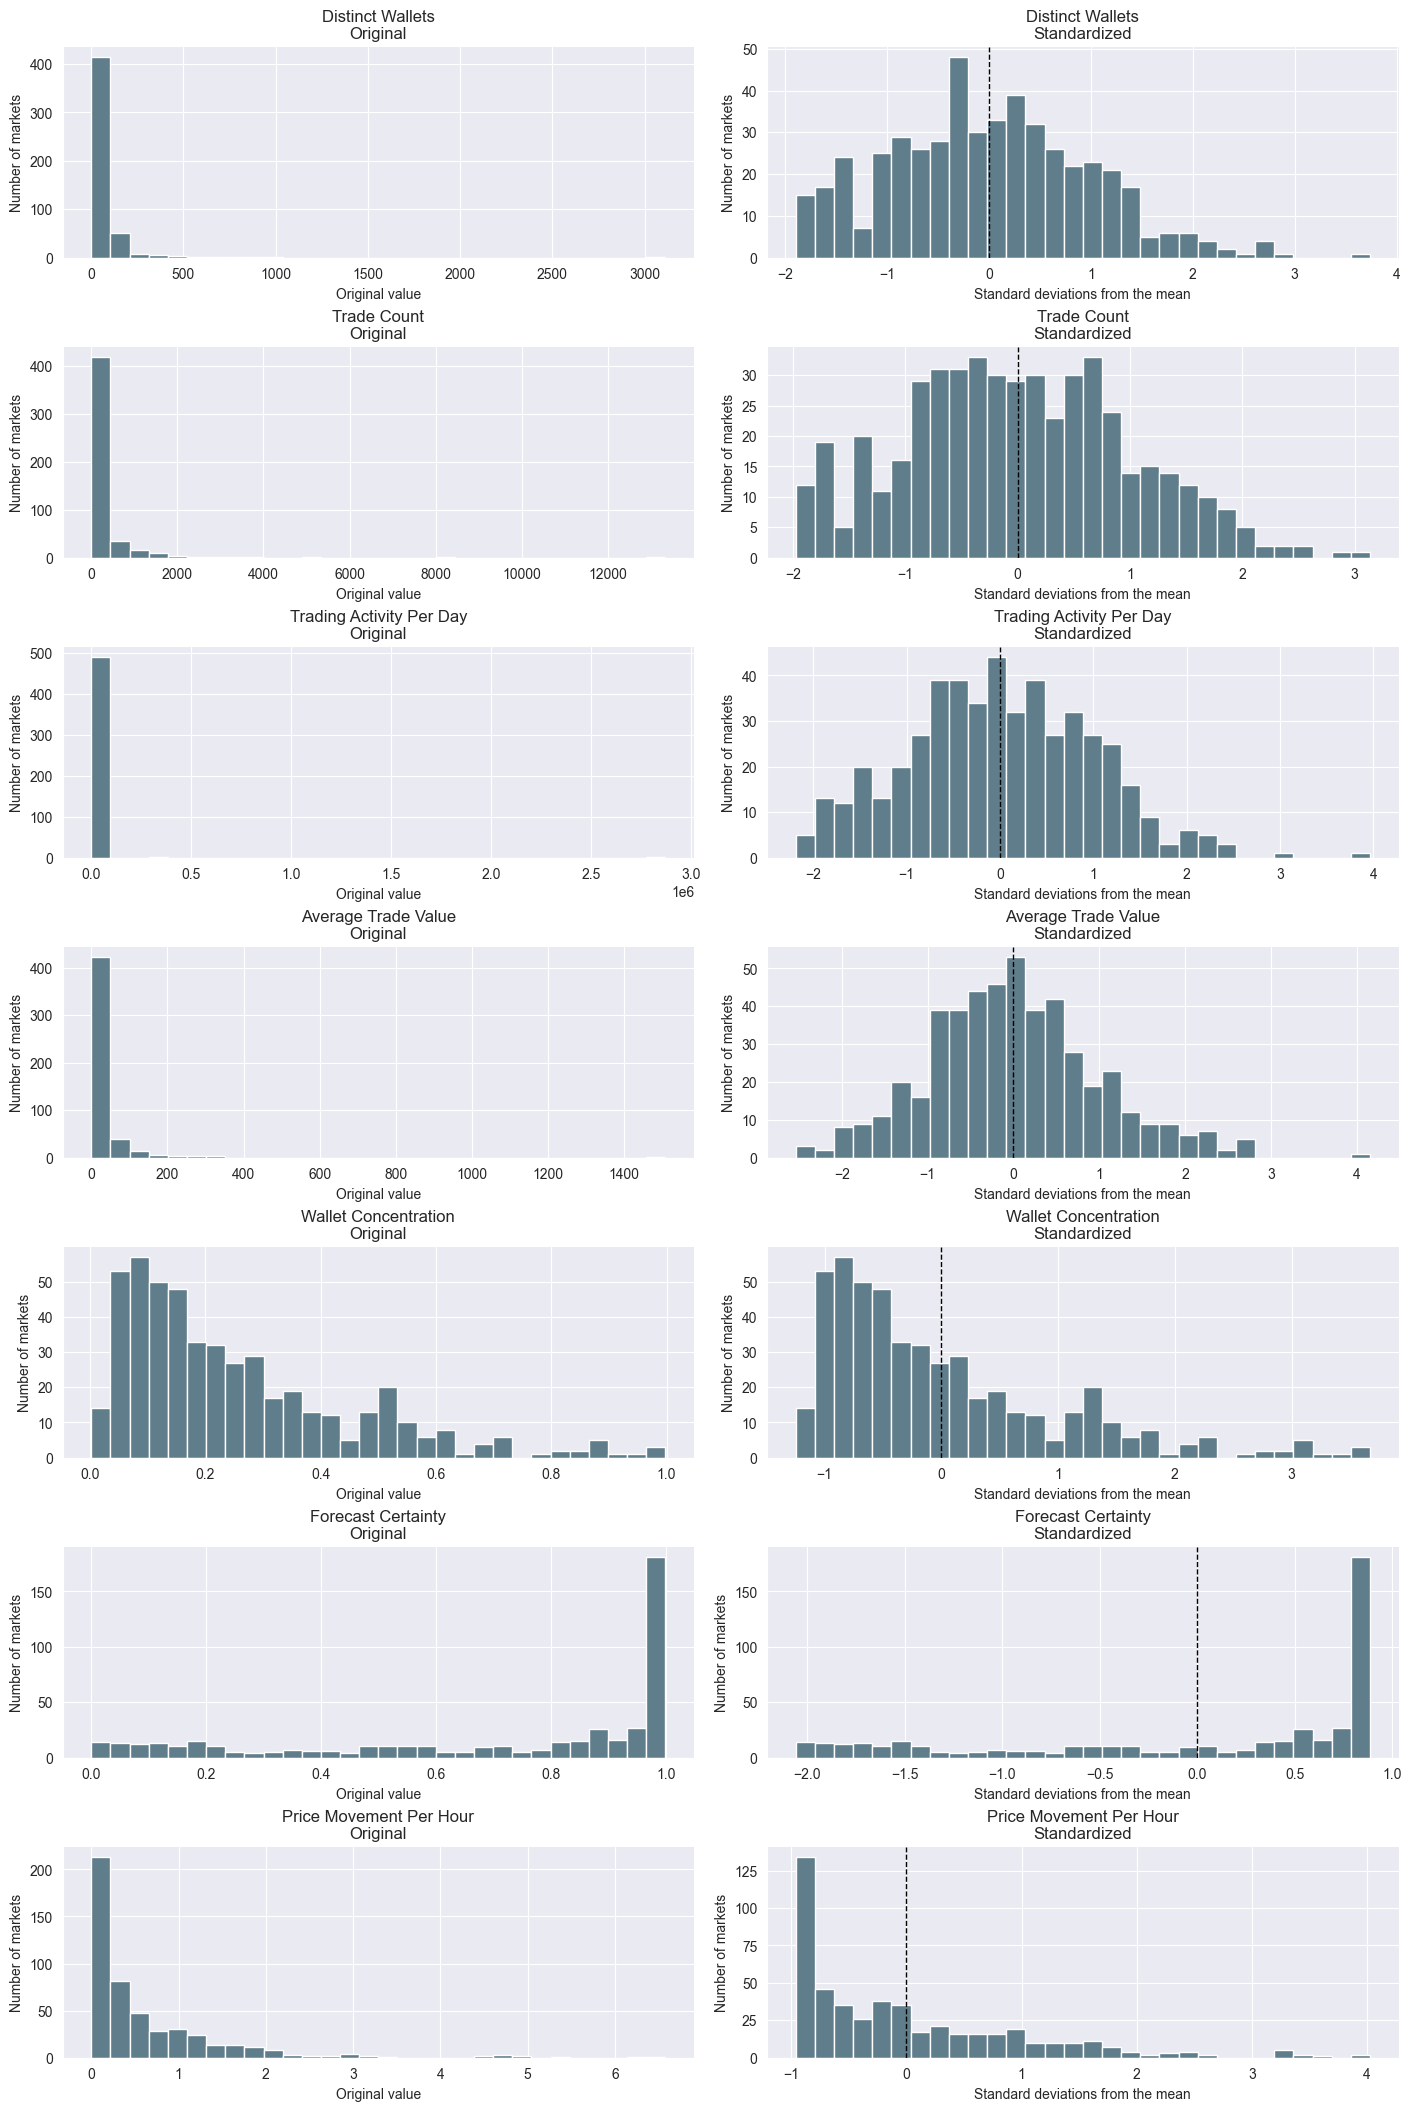

In [5]:
# check / plot distributions 

labels = {
    "observed_wallet_count": "Distinct Wallets",
    "wallet_trade_count": "Trade Count",
    "account_activity_per_observed_day":
        "Trading Activity Per Day",
    "mean_wallet_trade_notional": "Average Trade Value",
    "wallet_activity_hhi": "Wallet Concentration",
    "forecast_certainty": "Forecast Certainty",
    "price_movement_pp_per_hour":
        "Price Movement Per Hour",
}

fig, axes = plt.subplots(
    len(candidate_features),
    2,
    figsize=(14, 3 * len(candidate_features)),
    sharey=False,
    constrained_layout=True,
)

for row, feature in enumerate(candidate_features):
    # original feature measurements
    axes[row, 0].hist(
        X_candidates_raw[feature],
        bins=30,
        color="#607D8B",
        edgecolor="white",
    )
    axes[row, 0].set_title(f"{labels[feature]}\nOriginal")
    axes[row, 0].set_xlabel("Original value")
    axes[row, 0].set_ylabel("Number of markets")

    axes[row, 1].hist(
        X_candidates_scaled[feature],
        bins=30,
        color="#607D8B",
        edgecolor="white",
    )
    axes[row, 1].set_title(f"{labels[feature]}\nStandardized")
    axes[row, 1].set_xlabel("Standard deviations from the mean")
    axes[row, 1].set_ylabel("Number of markets")
    axes[row, 1].axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1,
    )

for plot_ax in axes.flat:
    plot_ax.spines["top"].set_visible(False)
    plot_ax.spines["right"].set_visible(False)
    plot_ax.tick_params(top=False, right=False)

plt.show()

wallet concentration, price momvement, have right skew. forecast certainty is skewed left

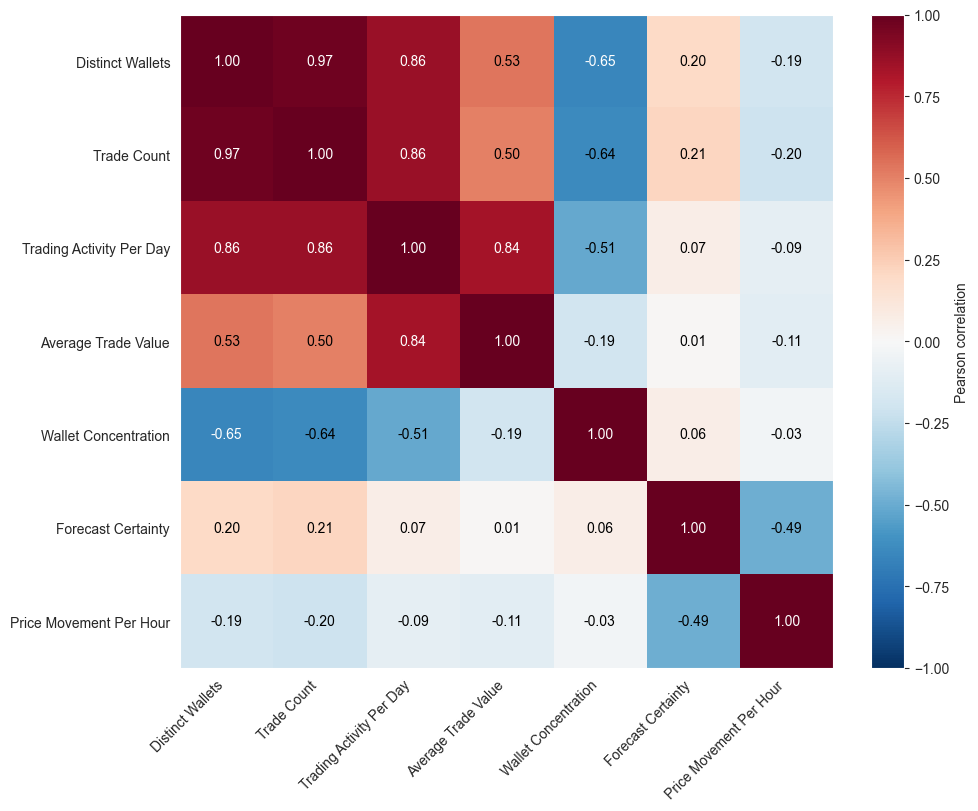

Wallet/trade-count correlation: 0.972


In [6]:
candidate_correlations = X_candidates_scaled.corr(
    method="pearson"
)

plot_correlations = candidate_correlations.rename(
    index=labels,
    columns=labels,
)

fig, ax = plt.subplots(
    figsize=(10, 8),
    constrained_layout=True,
)

heatmap = ax.imshow(
    plot_correlations,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
)

positions = np.arange(len(candidate_features))

ax.set_xticks(positions)
ax.set_yticks(positions)

ax.set_xticklabels(
    plot_correlations.columns,
    rotation=45,
    ha="right",
)
ax.set_yticklabels(plot_correlations.index)

for row in positions:
    for col in positions:
        value = plot_correlations.iloc[row, col]

        ax.text(
            col,
            row,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if abs(value) > 0.65 else "black",
        )

fig.colorbar(
    heatmap,
    ax=ax,
    label="Pearson correlation",
)

for axis in fig.axes:
    axis.grid(False, which="both")
plt.show()

wallet_trade_r = candidate_correlations.loc[
    "observed_wallet_count",
    "wallet_trade_count",
]

print(
    "Wallet/trade-count correlation: "
    f"{wallet_trade_r:.3f}"
)

In [214]:
# exclude wallet trade count from final model inputs
features = [
    feature
    for feature in candidate_features
    if feature != "wallet_trade_count"
]

# only include the final feature and re-transform/scale 
X_raw = X_candidates_raw[features].copy()
X_transformed = X_candidates_transformed[features].copy()

scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_transformed),
    columns=features,
    index=X_transformed.index,
)

print(f"Final model input shape: {X_scaled.shape}")
display(X_scaled.head(3))

Final model input shape: (492, 6)


,observed_wallet_count,account_activity_per_observed_day,mean_wallet_trade_notional,wallet_activity_hhi,forecast_certainty,price_movement_pp_per_hour
0,1.807076,1.390694,0.465563,-1.095745,-0.644021,0.842091
1,-1.662721,-1.719523,-0.900245,3.051295,0.686536,0.904476
2,0.370093,-0.287173,-0.790753,-0.529489,0.810446,-0.618452


In [215]:
display(X_raw.head(3))

,observed_wallet_count,account_activity_per_observed_day,mean_wallet_trade_notional,wallet_activity_hhi,forecast_certainty,price_movement_pp_per_hour
0,287.0,5739.911359,25.739513,0.032503,0.480,1.079954
1,3.0,2.145357,5.005833,0.872410,0.931,1.133346
2,48.0,98.908639,5.769671,0.147187,0.973,0.149078


In [202]:
# kmeans, test k = 1-8, 15 n_init

K_VALUES = range(1, 9)  # 1 through 8
N_INIT = 15
RANDOM_STATE = 0

print(f"Clustering input: {X_scaled.shape}")

# keep results for all values of k during tests
baseline_models = {}
baseline_labels = pd.DataFrame(index=X_scaled.index)
results = []

for k in K_VALUES:
    km = KMeans(n_clusters=k, init = "k-means++", n_init=N_INIT, random_state=RANDOM_STATE)
    cluster_ids = km.fit_predict(X_scaled)

    baseline_models[k] = km
    baseline_labels[k] = cluster_ids

    sizes = pd.Series(cluster_ids).value_counts()

    # sil score requires at least two clusters.
    sil = silhouette_score(X_scaled, cluster_ids) if k > 1 else np.nan

    results.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": sil,
        "smallest_cluster": sizes.min(),
        "largest_cluster": sizes.max(),
    })

baseline_results = pd.DataFrame(results)
inertias = baseline_results["inertia"].tolist()

display(baseline_results.round(3))

Clustering input: (492, 6)


,k,inertia,silhouette,smallest_cluster,largest_cluster
0,1,2952.000,NaN,492,492
1,2,2059.992,0.260,235,257
2,3,1666.473,0.254,122,189
3,4,1442.646,0.238,90,153
4,5,1272.075,0.235,57,152
5,6,1157.994,0.213,51,108
6,7,1053.940,0.245,48,120
7,8,974.189,0.242,24,105


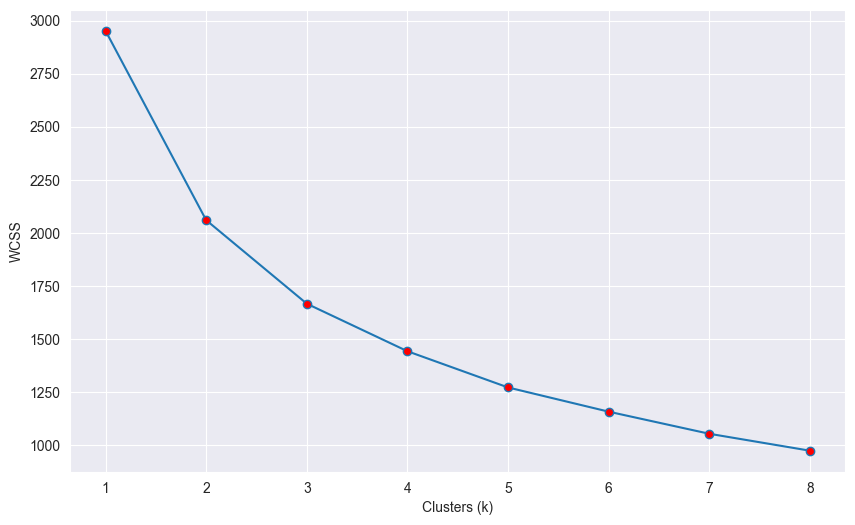

In [10]:
# elbow method 

plt.figure(figsize = (10,6))
sns.set_style('darkgrid')
plt.plot(range(1, len(inertias) + 1), inertias, marker = 'o', markerfacecolor = 'r')

plt.xlabel('Clusters (k)')
plt.ylabel('WCSS')
plt.show()

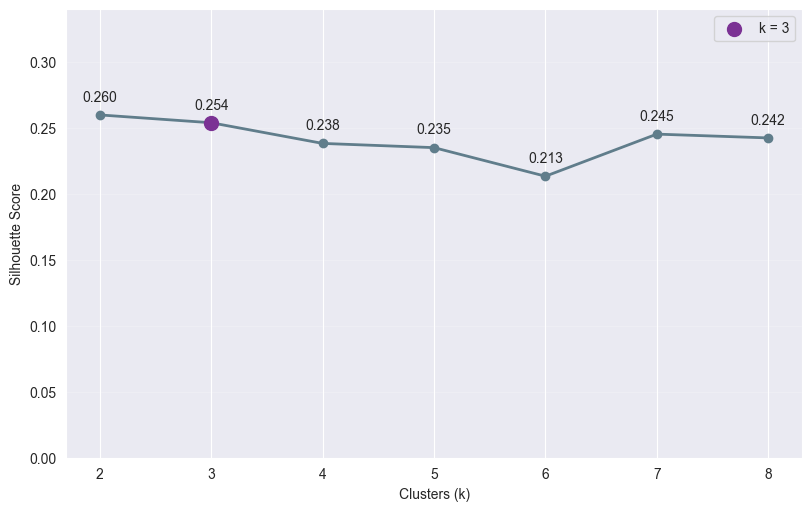

In [12]:
# get sil results
comp = (
    baseline_results
    .dropna(subset=["silhouette"])
    .sort_values("k")
)

fig, ax = plt.subplots(
    figsize=(8, 5),
    constrained_layout=True,
)

ax.plot(
    comp["k"],
    comp["silhouette"],
    marker="o",
    color="#607D8B",
    linewidth=2,
)

# add labels, rounded to 3
for row in comp.itertuples():
    ax.annotate(
        f"{row.silhouette:.3f}",
        (row.k, row.silhouette),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
    )

# seelct chosen k to highlight
chosen_score = comp.set_index("k").loc[3, "silhouette"]

ax.scatter(
    3,
    chosen_score,
    s=100,
    color="#7B3294",
    zorder=3,
    label="k = 3",
)

ax.set_xticks(comp["k"])
ax.set_ylim(0, comp["silhouette"].max() + 0.08)
ax.set_xlabel("Clusters (k)")
ax.set_ylabel("Silhouette Score")

ax.grid(axis="y", alpha=0.2)
ax.legend()

plt.show()

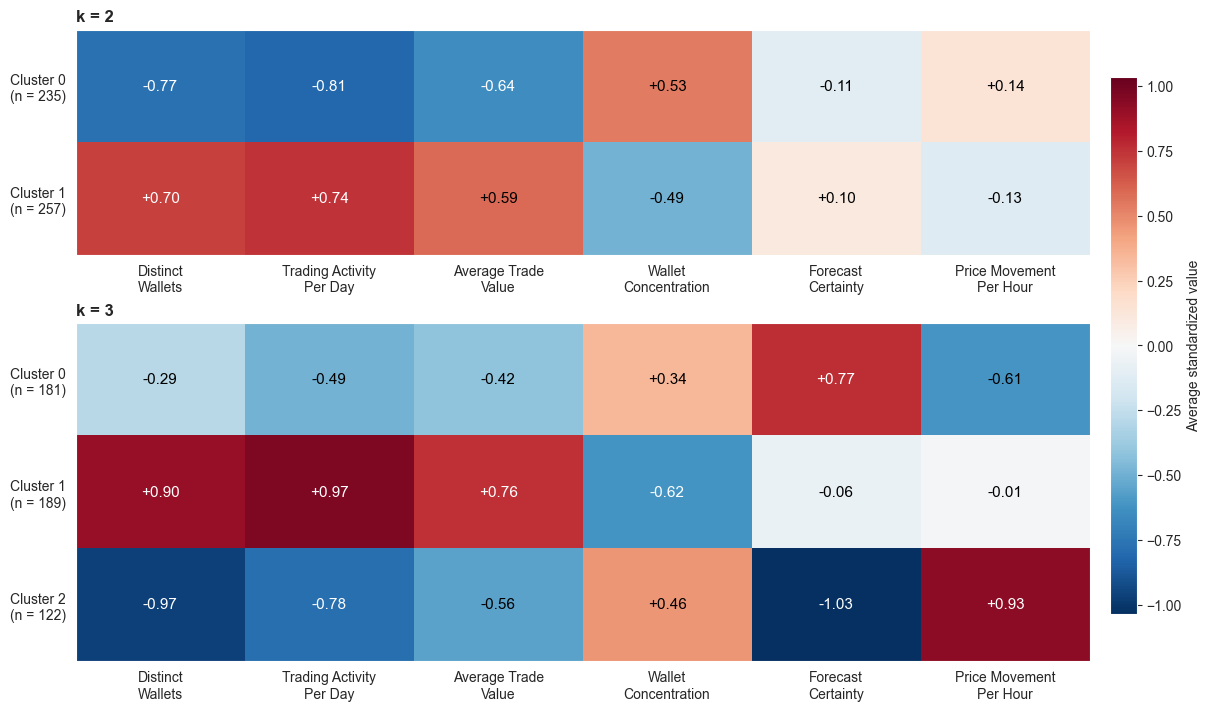

In [14]:

# add to plot more k results
KS_TO_PLOT = [2, 3]

feature_names = {
    "observed_wallet_count": "Distinct\nWallets",
    "account_activity_per_observed_day": "Trading Activity\nPer Day",
    "mean_wallet_trade_notional": "Average Trade\nValue",
    "wallet_activity_hhi": "Wallet\nConcentration",
    "forecast_certainty": "Forecast\nCertainty",
    "price_movement_pp_per_hour": "Price Movement\nPer Hour",
}


# find means for each feature in each cluster 
cluster_profiles = {
    k: X_scaled.groupby(baseline_labels[k]).mean()
    for k in KS_TO_PLOT
}

# set color scale and cetner it at 0
color_limit = max(
    1.0,
    max(
        np.abs(profile.to_numpy()).max()
        for profile in cluster_profiles.values()
    ),
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7),
    gridspec_kw={"height_ratios": KS_TO_PLOT},
    constrained_layout=True,
)

for ax, k in zip(axes, KS_TO_PLOT):
    profile = cluster_profiles[k]
    counts = baseline_labels[k].value_counts()

    heatmap = ax.imshow(
        profile.to_numpy(),
        cmap="RdBu_r",
        vmin=-color_limit,
        vmax=color_limit,
        aspect="auto",
        interpolation="nearest",
    )

    ax.set_xticks(np.arange(len(profile.columns)))
    ax.set_xticklabels(
        [feature_names[column] for column in profile.columns],
        fontsize=10,
    )

    ax.set_yticks(np.arange(len(profile)))
    ax.set_yticklabels([
        f"Cluster {cluster_id}\n(n = {counts.loc[cluster_id]})"
        for cluster_id in profile.index
    ])

    # add average val label
    for (row, col), value in np.ndenumerate(profile.to_numpy()):
        ax.text(
            col, row,
            f"{value:+.2f}",
            ha="center",
            va="center",
            fontsize=11,
            color=(
                "white"
                if abs(value) > 0.6 * color_limit
                else "black"
            ),
        )

    ax.set_title(f"k = {k}", loc="left", fontweight="bold")

fig.colorbar(
    heatmap,
    ax=axes.tolist(),
    label="Average standardized value",
    shrink=0.85,
    pad=0.02,
)


# remove gridlines
for axis in fig.axes:
    axis.grid(False, which="both")
plt.show()




- **k = 2:** Cluster 0 (235 markets) has lower participation/activity and smaller wallet trades, with higher concentration. Cluster 1 (257) shows the opposite profile.
- **k = 3:** Cluster 0 (181 markets) has below-average participation/activity, higher forecast certainty and less price movement. Cluster 1 (189) has higher participation/activity, larger wallet trades and lower concentration, with certainty and movement near average. Cluster 2 (122) has fewer wallets and lower activity, higher concentration, lower certainty and more movement.



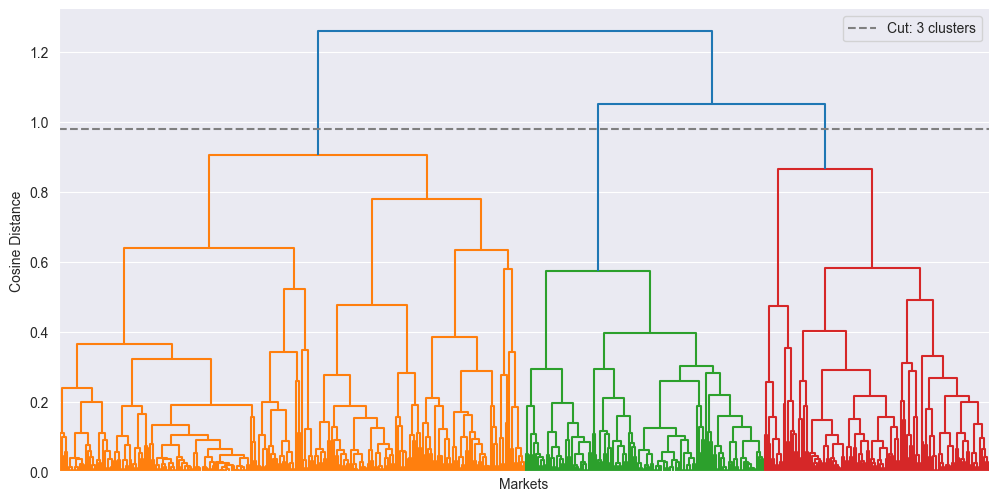

In [16]:
Z = linkage(X_scaled, method="average", metric="cosine")

# set max number of clusters
t = 3

# cut midway between the merge leaving 3 groups and the next merge leaving 2.
# print(Z)
cut_height = (Z[-3, 2] + Z[-2, 2]) / 2

plt.figure(figsize=(12, 6))
dendrogram(Z, color_threshold=cut_height, no_labels = True)
plt.axhline(
    cut_height, color="grey", linestyle="--",
    label=f"Cut: {t} clusters"
)

plt.xlabel("Markets")
plt.ylabel("Cosine Distance")
plt.legend()
plot_ax = plt.gca()
plot_ax.spines["top"].set_visible(False)
plot_ax.spines["right"].set_visible(False)
plot_ax.tick_params(top=False, right=False)

plt.show()

h_labels = fcluster(Z, t=t, criterion="maxclust")

Three hierarchical groups are retained for the descriptive comparison with k-means. The cut does not establish a uniquely correct number of clusters. Review the refreshed dendrogram and cross-method comparison when writing the interpretation.

Adjusted Rand Index: 0.487


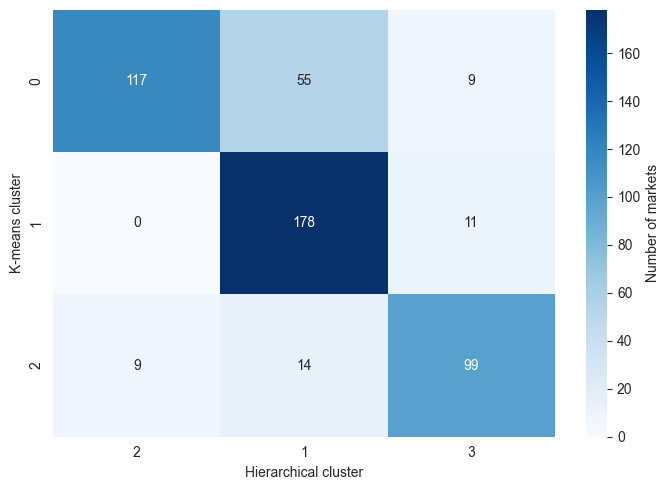

In [18]:
# get comparison cluster labels
compare_methods = pd.DataFrame(index=X_scaled.index)
compare_methods["K-means"] = baseline_labels[3].loc[X_scaled.index]
compare_methods["Hierarchical"] = h_labels

# crosstab cluster labels
overlap = pd.crosstab(
    compare_methods["K-means"],
    compare_methods["Hierarchical"],
    margins=True,
)
#display(overlap)

# compute adjusted rand index
ari = adjusted_rand_score(
    compare_methods["K-means"],
    compare_methods["Hierarchical"],
)
print(f"Adjusted Rand Index: {ari:.3f}")

#align on the diagonal 
counts = overlap.drop(index="All", columns="All")
counts = counts.loc[:, [2, 1, 3]]

fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(
    counts,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0,
    cbar_kws={"label": "Number of markets"},
    ax=ax,
)

ax.grid(False)
ax.set_xlabel("Hierarchical cluster")
ax.set_ylabel("K-means cluster")


plt.tight_layout()
plt.show()

In [208]:
# save inputs and fitted results for reproducibility
analysis_dir = ROOT / "data" / "analysis" / "20261008_wallet_trades" / "clustering"
analysis_dir.mkdir(parents=True, exist_ok=True)
X_raw.to_csv(analysis_dir / "input_raw.csv", index=False)
X_scaled.to_csv(analysis_dir / "input_scaled.csv", index=False)
metadata.to_csv(analysis_dir / "market_metadata.csv", index=False)
baseline_results.to_csv(analysis_dir / "kmeans_results.csv", index=False)
assignments = metadata[["market_id", "topic"]].join(baseline_labels.add_prefix("kmeans_k"))
assignments["hierarchical_k3"] = h_labels
assignments.to_csv(analysis_dir / "assignments.csv", index=False)
for k, profile in cluster_profiles.items():
    profile.to_csv(analysis_dir / f"kmeans_k{k}_profiles.csv")
overlap.to_csv(analysis_dir / "method_overlap.csv")
print(f"Current results saved to {analysis_dir.relative_to(ROOT)}")


Current results saved to data\analysis\20261008_wallet_trades\clustering


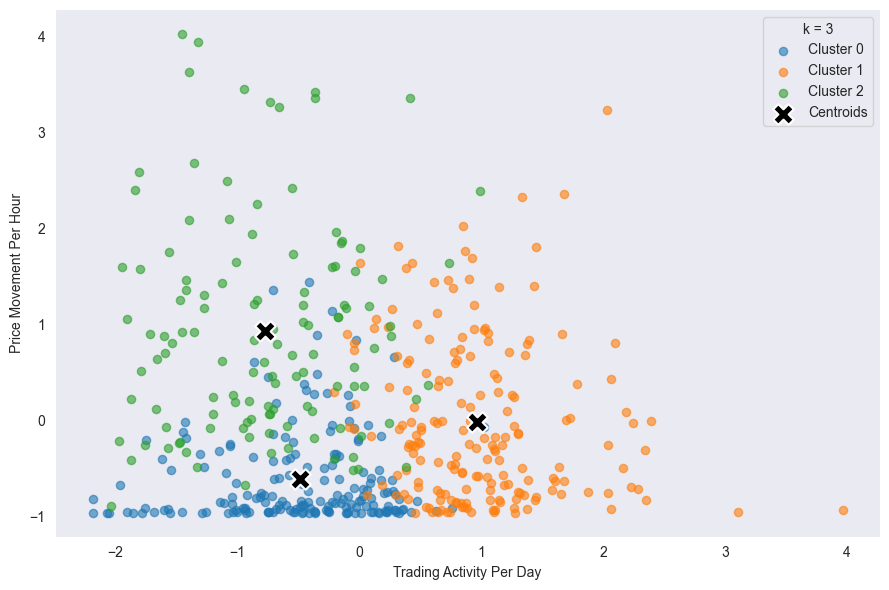

In [20]:
# exmaple kmeans plot for overview

fig, ax = plt.subplots(figsize=(9, 6))

for cluster in sorted(baseline_labels[3].unique()):
    mask = baseline_labels[3] == cluster

    ax.scatter(
        X_scaled.loc[mask, "account_activity_per_observed_day"],
        X_scaled.loc[mask, "price_movement_pp_per_hour"],
        label=f"Cluster {cluster}",
        alpha=0.6,
        s=35,
    )

ax.set_xlabel("Trading Activity Per Day")
ax.set_ylabel("Price Movement Per Hour")


# add centroids 
centers = baseline_models[3].cluster_centers_

x_col = X_scaled.columns.get_loc("account_activity_per_observed_day")
y_col = X_scaled.columns.get_loc("price_movement_pp_per_hour")

ax.scatter(
    centers[:, x_col],
    centers[:, y_col],
    marker="X",
    s=220,
    color="black",
    edgecolor="white",
    linewidth=1.5,
    label="Centroids",
    zorder=5,
)
ax.legend(title="k = 3")
ax.grid(False)

plt.tight_layout()
plot_ax = plt.gca()
plot_ax.spines["top"].set_visible(False)
plot_ax.spines["right"].set_visible(False)
plot_ax.tick_params(top=False, right=False)

plt.show()

Cluster,0,1,2,Total
topic,,,,
Sports,10,40,81,131
Politics,106,78,13,197
Economics,65,71,28,164


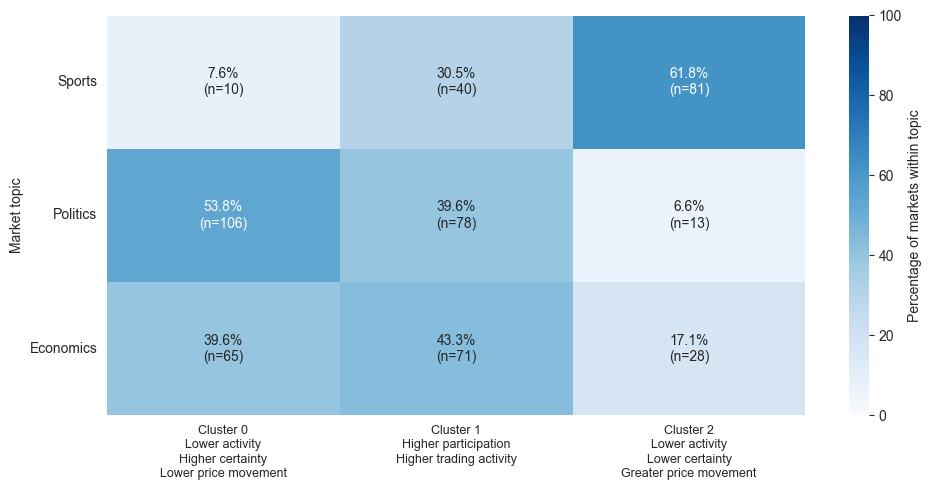

In [218]:
# match topics to clusters
topic_cluster = metadata.loc[X_scaled.index, ["topic"]].copy()
topic_cluster["Cluster"] = baseline_labels[3].loc[X_scaled.index]

topic_order = ["Sports", "Politics", "Economics"]

# count markets in topic-cluister crossovers
topic_counts = pd.crosstab(
    topic_cluster["topic"],
    topic_cluster["Cluster"],
).reindex(
    index=topic_order,
    columns=[0, 1, 2],
    fill_value=0,
)

display(topic_counts.assign(Total=topic_counts.sum(axis=1)))

# percentages within each topic  (each row sums to 100%
topic_percent = topic_counts.div(
    topic_counts.sum(axis=1),
    axis=0,
) * 100

# show both percentages and #
annotations = (
    topic_percent.round(1).astype(str)
    + "%\n(n="
    + topic_counts.astype(str)
    + ")"
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.heatmap(
    topic_percent,
    annot=annotations,
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0,
    cbar_kws={"label": "Percentage of markets within topic"},
    ax=ax,
)

ax.set_xlabel("K-means cluster")
ax.set_ylabel("Market topic")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.grid(False)

# add cluster descriptions for readability 
ax.set_xticklabels(
    [
        "Cluster 0\nLower activity\nHigher certainty\nLower price movement",
        "Cluster 1\nHigher participation\nHigher trading activity",
        "Cluster 2\nLower activity\nLower certainty\nGreater price movement",
    ],
    rotation=0,
    fontsize=9,
)

ax.set_xlabel("")  

plt.tight_layout()
plt.show()